# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import Sentinel2CloudCoverSegmentationDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose
import numpy as np

## Visualize images and masks

2025-06-11 08:32:53,479 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


Total number of patches: 9497


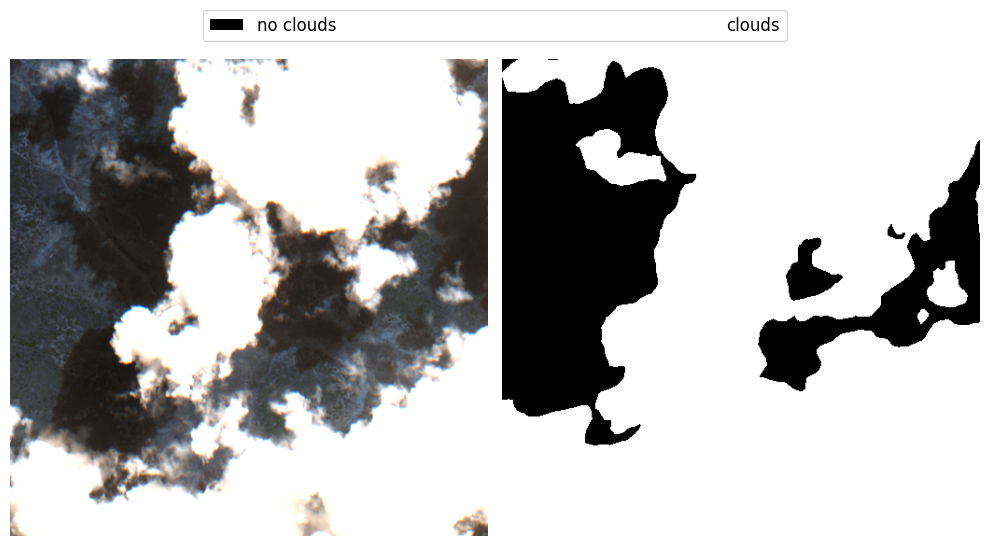

2025-06-11 08:32:53,731 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


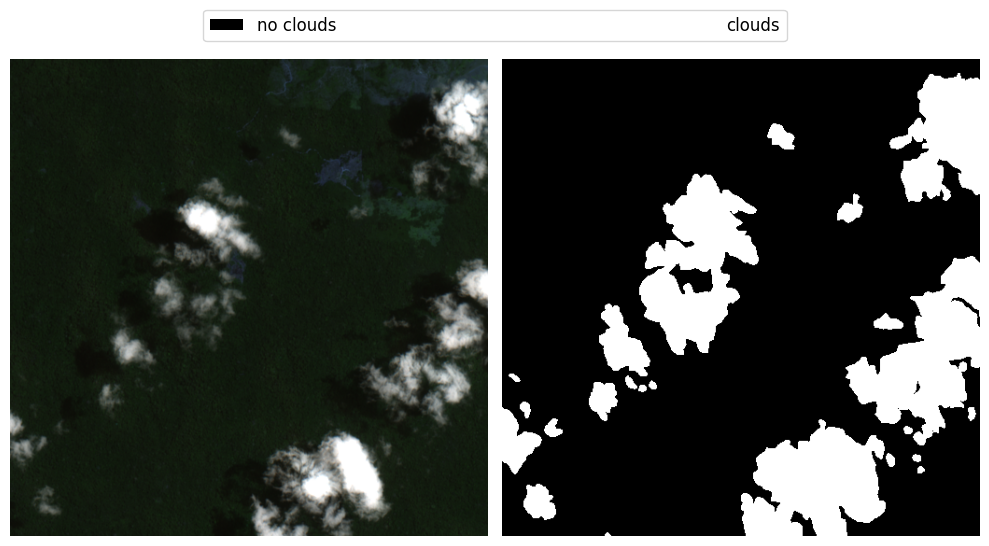

2025-06-11 08:32:53,989 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


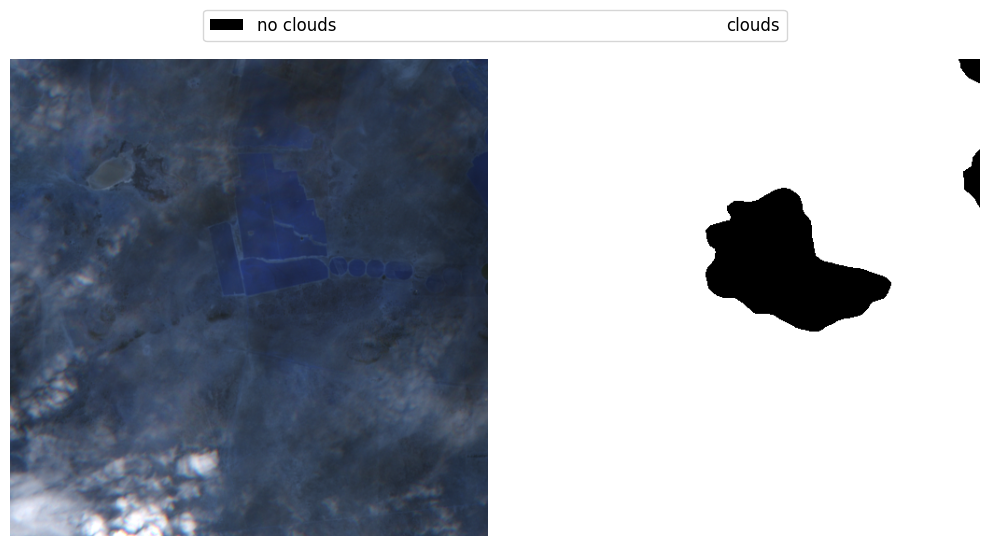

In [20]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/train/"
}
dataset = Sentinel2CloudCoverSegmentationDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(1500);

In [21]:
dataset.data_distribution_table()

,Number of pixels
no clouds,9.502920e+08
clouds,1.539290e+09


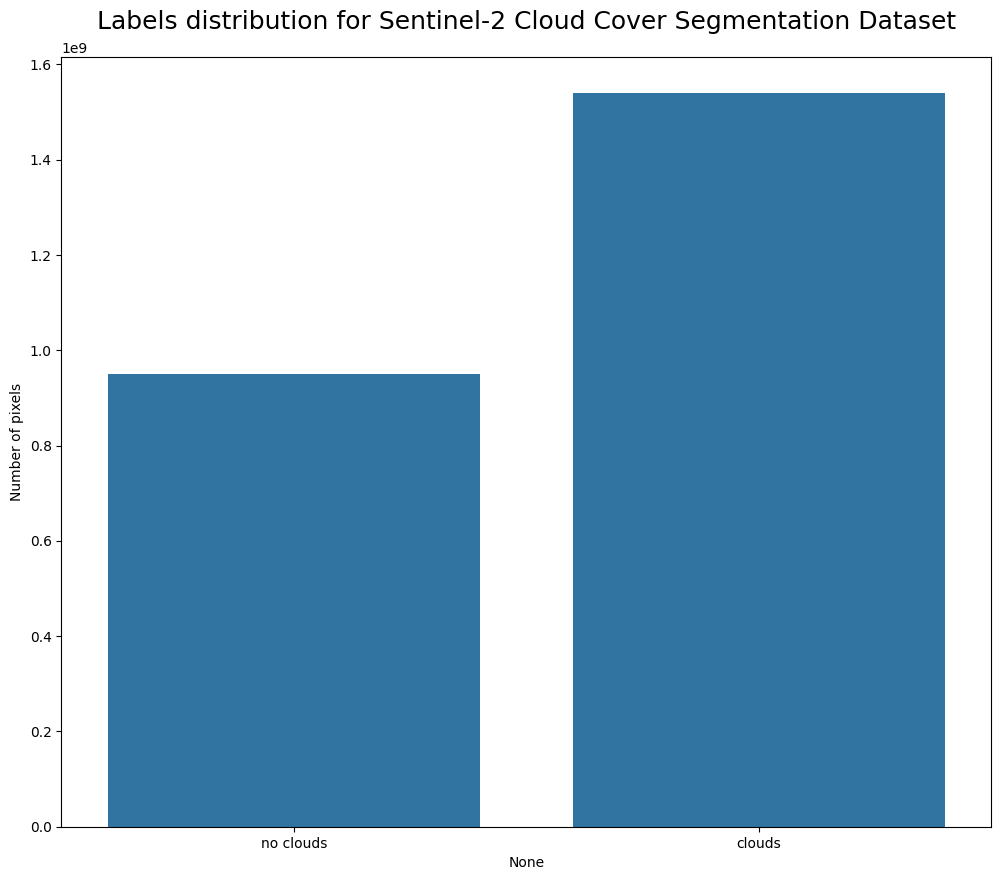

In [22]:
dataset.data_distribution_barchart();

## Load training data

In [4]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = Sentinel2CloudCoverSegmentationDataset(train_dataset_config)
len(train_dataset)

9497

## Create the model

In [5]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-06-11 08:41:19,827 INFO Starting training.
training: 100%|██████████| 594/594 [01:33<00:00,  6.33it/s]
2025-06-11 08:42:53,766 INFO epoch: 1, time: 94, loss:  0.26083
testing on train set: 100%|██████████| 594/594 [00:32<00:00, 18.07it/s]
2025-06-11 08:43:28,298 INFO IOU:0.6254888872442611, IOU mean:0.6219766303837779, IOU per Class:[0.57618801 0.66776526]
training: 100%|██████████| 594/594 [01:34<00:00,  6.27it/s]
2025-06-11 08:45:03,070 INFO epoch: 2, time: 95, loss:  0.22424
testing on train set: 100%|██████████| 594/594 [00:33<00:00, 17.48it/s]
2025-06-11 08:45:37,071 INFO IOU:0.6452941207285283, IOU mean:0.6409406449600634, IOU per Class:[0.59750355 0.68437774]
training: 100%|██████████| 594/594 [01:35<00:00,  6.25it/s]
2025-06-11 08:47:12,105 INFO epoch: 3, time: 95, loss:  0.21690
testing on train set: 100%|██████████| 594/594 [00:33<00:00, 17.52it/s]
2025-06-11 08:47:46,036 INFO IOU:0.6518432042454851, IOU mean:0.6440776610057298, IOU per Class:[0.60441572 0.68373961]
trai

## Evaluate the model

In [7]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = Sentinel2CloudCoverSegmentationDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

10980


2025-06-11 09:02:48,328 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar
2025-06-11 09:02:48,803 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2745/2745 [00:50<00:00, 54.81it/s]


[{'IOU': 0.6195001798210917,
  'IOU mean': 0.615536990689479,
  'IOU per Class': array([0.57524359, 0.65583039])}]

## Predictions

2025-06-11 09:05:02,360 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar
2025-06-11 09:05:02,817 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar at epoch 11
2025-06-11 09:05:02,870 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-06-11 09:05:02,975 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-06-11 09:05:03,080 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


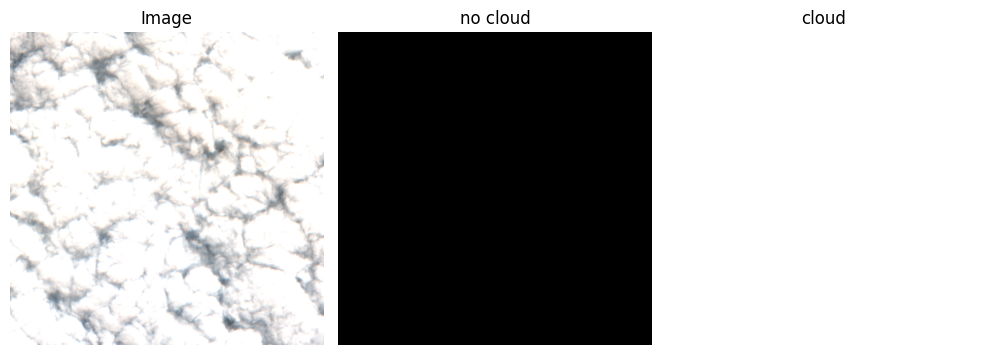

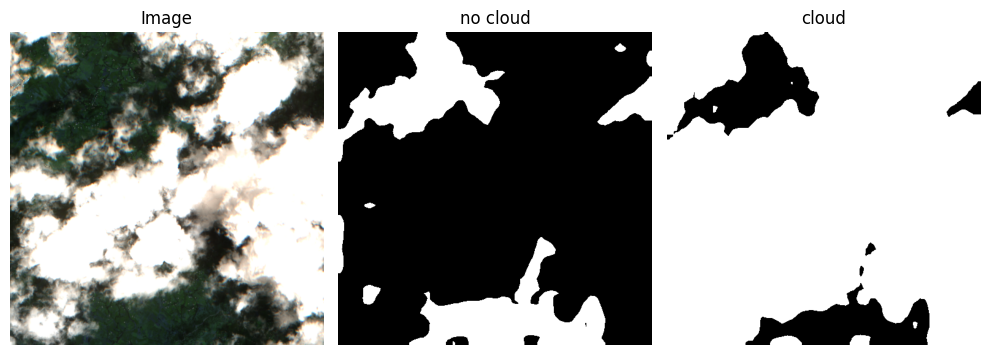

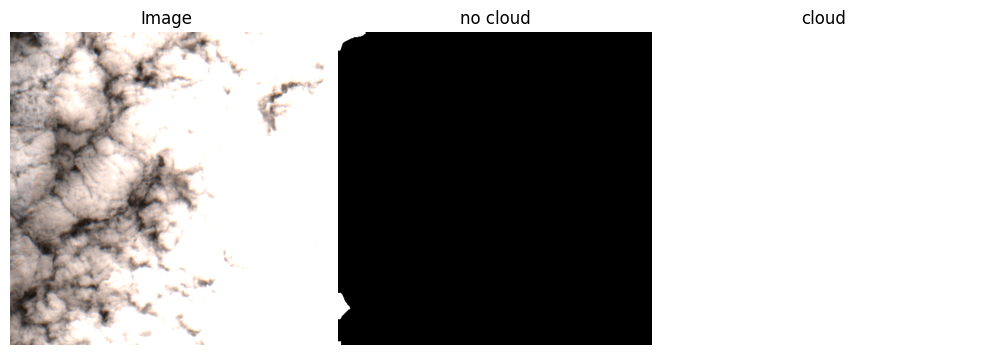

In [11]:
model_path = "/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/checkpoint.pth.tar"
labels = ["no cloud","cloud"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

imageB02 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B02.tif')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B03.tif')
imageB04 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/aabd/B04.tif')
image = np.dstack((imageB02,imageB03,imageB04))/5000
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B02.tif')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B03.tif')
imageB04 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/lgwg/B04.tif')
image = np.dstack((imageB02,imageB03,imageB04))/5000
fig = model.predict_masks(image, labels, transform)

imageB02 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/quif/B02.tif')
imageB03 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/quif/B03.tif')
imageB04 = image_loader('/home/dragik/data/FAIR_EO/Sentinel-2_cloud_cover_segmentation/test/features/quif/B04.tif')
image = np.dstack((imageB02,imageB03,imageB04))/5000
fig = model.predict_masks(image, labels, transform)